# Bank Marketing 

**Задача:** изучить данные телефонных кампаний банка и выяснить, можно ли по информации, известной до звонка, предсказать согласие клиента открыть депозит (`y`).

**Источник:** [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), файл `bank-full.csv`. Рядом с ноутбуком должен быть CSV датасета. Библиотеки: `pandas`, `matplotlib`, `seaborn`.

## 1. Таблица

Размер, названия колонок и несколько строк. Затем основные статистики по всем 17 столбцам

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("bank-full.csv", sep=";")
print("Размер:", df.shape)
display(df.head())

Размер: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()
display(df.describe(include="all").T.round(2))

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


45 211 строк, 16 входных признаков и `y`. Числовых входных признаков семь; остальные категориальные. `balance` может быть отрицательным. `pdays` содержит `-1`: нужно открыть описание признака и проверить смысл этого значения.

## 2. Таргет

Сколько клиентов согласилось открыть депозит. Если положительный класс редкий, одной accuracy в будущем будет недостаточно.

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


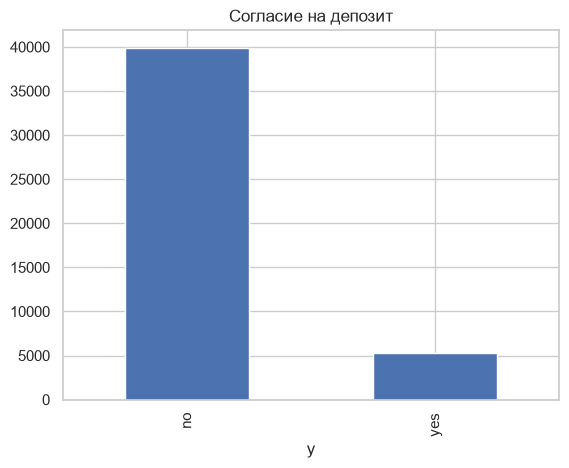

In [4]:
print(df["y"].value_counts())
print((df["y"].value_counts(normalize=True) * 100).round(2))
df["y"].value_counts().reindex(["no", "yes"]).plot.bar()
plt.title("Согласие на депозит")
plt.show()

`no` - 39 922 (88,30%), `yes` - 5 289 (11,70%). Для сценария поиска откликнувшихся клиентов понадобится метрика, учитывающая редкий положительный класс; конкретный выбор зависит от цели кампании и цены ошибок.

## 3. Пропуски, дубликаты, специальные обозначения

`isna()` покажет формальные пропуски, но в категориальных столбцах отсутствие информации может быть записано словом `unknown`.

In [5]:
missing = pd.DataFrame({
    "NaN": df.isna().sum(),
    "NaN, %": (100 * df.isna().mean()).round(2),
    "unknown": df.eq("unknown").sum(),
    "unknown, %": (100 * df.eq("unknown").mean()).round(2)
})
display(missing)
print("Дубликаты строк:", df.duplicated().sum())
print("Всего unknown:", int(df.eq("unknown").sum().sum()))
print("unknown среди входных признаков, %:",
      round(100 * df.drop(columns="y").eq("unknown").to_numpy().mean(), 2))

,NaN,"NaN, %",unknown,"unknown, %"
age,0,0.0,0,0.00
job,0,0.0,288,0.64
marital,0,0.0,0,0.00
education,0,0.0,1857,4.11
default,0,0.0,0,0.00
balance,0,0.0,0,0.00
housing,0,0.0,0,0.00
loan,0,0.0,0,0.00
contact,0,0.0,13020,28.80
day,0,0.0,0,0.00


Дубликаты строк: 0
Всего unknown: 52124
unknown среди входных признаков, %: 7.21


Обычных `NaN` и полных дубликатов нет. Но слово `unknown` встречается 52 124 раза в четырёх столбцах (`job`, `education`, `contact`, `poutcome`): около 7,21% ячеек входных признаков. Смысл `unknown` различается от столбца к столбцу.

В описании UCI сказано, что `pdays = -1` означает отсутствие контакта в предыдущей кампании.

In [6]:
print("pdays = -1:", (df["pdays"] == -1).sum(),
      "(%, строк):", round(100 * (df["pdays"] == -1).mean(), 2))
display(pd.crosstab(df["pdays"] == -1, df["poutcome"]))

pdays = -1: 36954 (%, строк): 81.74


poutcome,failure,other,success,unknown
pdays,,,,
False,4901,1840,1511,5
True,0,0,0,36954


36 954 клиента не участвовали в предыдущей кампании; у всех них `poutcome = unknown`. Ещё у 5 клиентов `poutcome = unknown`, хотя прежний контакт был.

## 4. Ошибки и выбросы

Проверка очевидных ограничений на значения. Границы для возраста - проверка правдоподобия.

In [7]:
print("Возраст вне 0–120:", (~df["age"].between(0, 120)).sum())
print("День вне 1–31:", (~df["day"].between(1, 31)).sum())
print("Отрицательная длительность:", (df["duration"] < 0).sum())
print("Количество звонков < 1:", (df["campaign"] < 1).sum())
print("Отрицательный баланс:", (df["balance"] < 0).sum())

Возраст вне 0–120: 0
День вне 1–31: 0
Отрицательная длительность: 0
Количество звонков < 1: 0
Отрицательный баланс: 3766


Очевидных нарушений проверенных диапазонов нет. Отрицательный баланс встречается у 3 766 клиентов, но это может быть реальный долг/овердрафт.

Надо посмотреть распределения каждого числового признака и затем отметить потенциальные выбросы методом IQR. Этот метод только подсвечивает необычные значения.

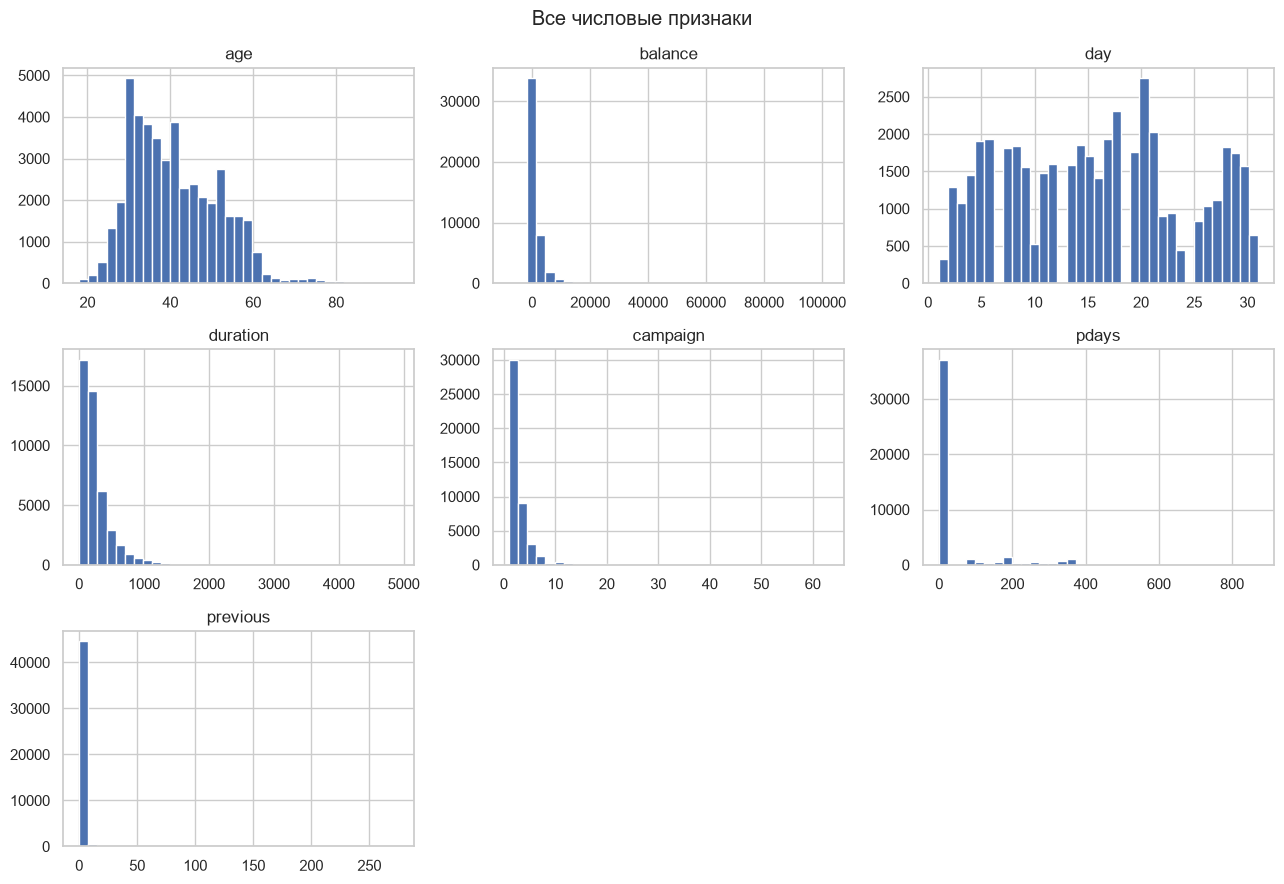

In [8]:
df.select_dtypes("number").hist(bins=35, figsize=(13, 9))
plt.suptitle("Все числовые признаки")
plt.tight_layout()
plt.show()

In [9]:
cols = ["age", "balance", "duration", "campaign"]
num = df[cols]
q1, q3 = num.quantile(.25), num.quantile(.75)
iqr = q3 - q1
flag = num.lt(q1 - 1.5 * iqr) | num.gt(q3 + 1.5 * iqr)
display(pd.DataFrame({"IQR-выбросы": flag.sum(),
                      "Доля, %": (flag.mean() * 100).round(2)}))

,IQR-выбросы,"Доля, %"
age,487,1.08
balance,4729,10.46
duration,3235,7.16
campaign,3064,6.78


In [10]:
has_history = df["pdays"] != -1
print("Есть история контактов:", has_history.sum(),
      f"({has_history.mean() * 100:.2f}%)")
print("previous = 0:", (df["previous"] == 0).sum())
print("Группы совпадают:", (has_history == (df["previous"] > 0)).all())
display(df.loc[has_history, ["pdays", "previous"]].describe().round(2))

Есть история контактов: 8257 (18.26%)
previous = 0: 36954
Группы совпадают: True


,pdays,previous
count,8257.00,8257.00
mean,224.58,3.18
std,115.34,4.56
min,1.00,1.00
25%,133.00,1.00
50%,194.00,2.00
75%,327.00,4.00
max,871.00,275.00


По IQR потенциальные выбросы найдены у `age`, `balance`, `duration` и `campaign`. Их наличие само по себе не означает ошибку в данных.

Для `pdays` и `previous` общий IQR не использовался. Без истории контактов - 36 954 клиента (`pdays = -1`, `previous = 0`). С историей - 8 257 (18,26%): `pdays` от 1 до 871, медиана 194; `previous` от 1 до 275, медиана 2. Эти значения исследованы отдельно.

## 5. Каждый категориальный признак отдельно

Сравнение частоты категорий во всех девяти категориальных входных признаках. Это должно помочь заметить редкие группы и `unknown`.

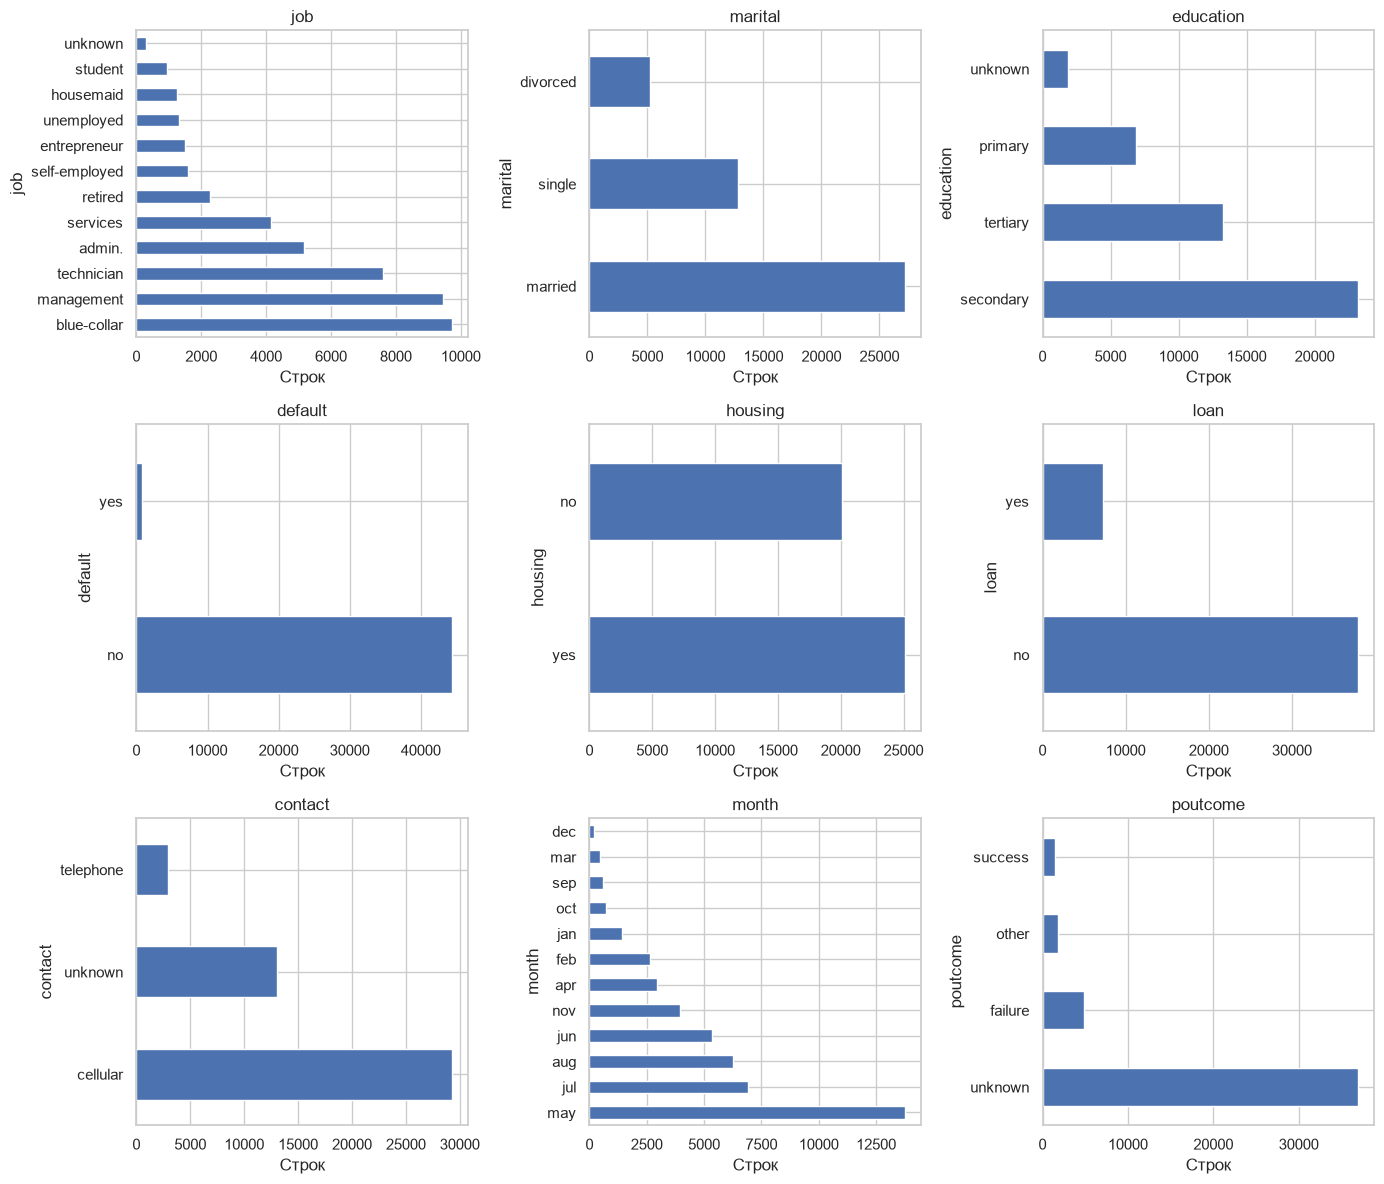

In [11]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("y")
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for col, ax in zip(cat_cols, axes.flat):
    df[col].value_counts().plot.barh(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Строк")
plt.tight_layout()
plt.show()

Группы существенно различаются по размеру. Например, в `contact` категория `unknown` велика, а `job=student` и `month=dec` намного реже основных категорий.

## 6. Связи признаков с целевой переменной

Для изучения всех категориальных признаков необходимо посчитать по каждой категории количество клиентов и процент `yes`. Для числовых сравню медианы по двум группам.

In [12]:
work = df.copy() 
work["target"] = work["y"].eq("yes").astype(int)
for col in cat_cols:
    t = work.groupby(col)["target"].agg(["size", "mean"])
    t["mean"] = (100 * t["mean"]).round(2)
    print(f"{col}: size = клиентов, mean = % 'yes'")
    display(t.sort_values("mean", ascending=False))

job: size = клиентов, mean = % 'yes'


,size,mean
job,,
student,938,28.68
retired,2264,22.79
unemployed,1303,15.50
management,9458,13.76
admin.,5171,12.20
self-employed,1579,11.84
unknown,288,11.81
technician,7597,11.06
services,4154,8.88


marital: size = клиентов, mean = % 'yes'


,size,mean
marital,,
single,12790,14.95
divorced,5207,11.95
married,27214,10.12


education: size = клиентов, mean = % 'yes'


,size,mean
education,,
tertiary,13301,15.01
unknown,1857,13.57
secondary,23202,10.56
primary,6851,8.63


... (8 outputs left out)

month: size = клиентов, mean = % 'yes'


,size,mean
month,,
mar,477,51.99
dec,214,46.73
sep,579,46.46
oct,738,43.77
apr,2932,19.68
feb,2649,16.65
aug,6247,11.01
jun,5341,10.22
nov,3970,10.15


poutcome: size = клиентов, mean = % 'yes'


,size,mean
poutcome,,
success,1511,64.73
other,1840,16.68
failure,4901,12.61
unknown,36959,9.16


In [13]:
num_cols = df.select_dtypes("number").columns
display(df.groupby("y")[list(num_cols)].median().T)
print("previous: среднее по y")
print(df.groupby("y")["previous"].mean().round(2))
print("Отклик с/без прежнего контакта, %:")
print((100 * work.groupby(df["pdays"].ne(-1))["target"].mean()).round(2))

y,no,yes
age,39.0,38.0
balance,417.0,733.0
day,16.0,15.0
duration,164.0,426.0
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


previous: среднее по y
y
no     0.50
yes    1.17
Name: previous, dtype: float64
Отклик с/без прежнего контакта, %:
pdays
False     9.16
True     23.07
Name: target, dtype: float64


У клиентов без жилищного кредита отклик около 16,7% против 7,7% у клиентов с ним; у `contact=unknown` - около 4,1% против 14,9% для `cellular`; после прежней успешной кампании (`poutcome=success`) доля `yes` - 64,7%, но там всего 1 511 клиентов. Связи могут объясняться отбором клиентов, историей кампаний и временем - это не причинные эффекты.

Надо построить пару графиков для наиболее заметных различий.

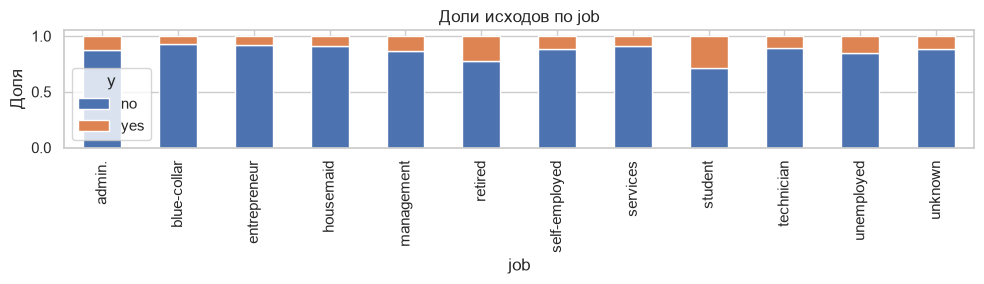

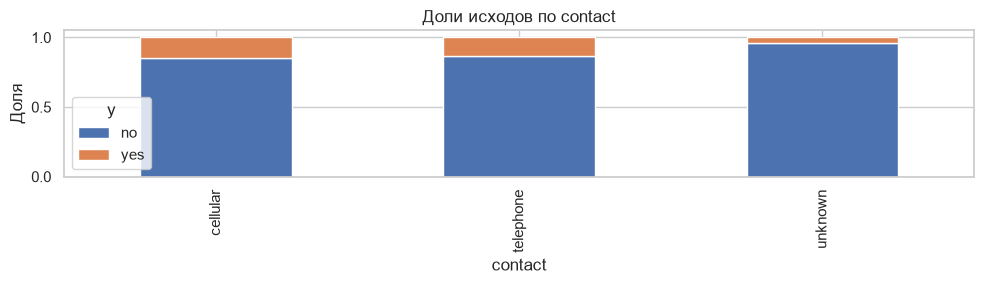

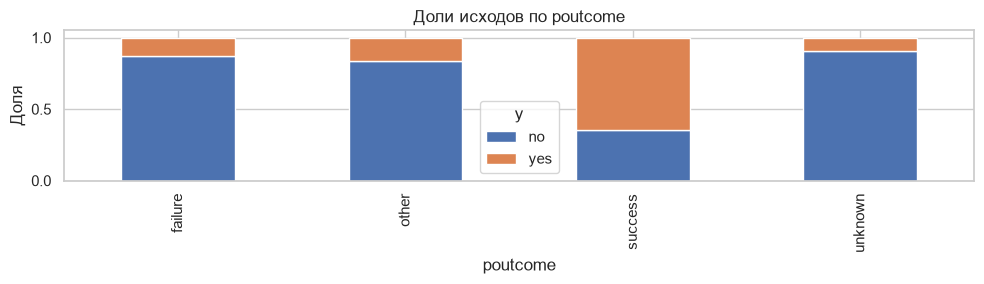

In [14]:
for col in ["job", "contact", "poutcome"]:
    pd.crosstab(df[col], df["y"], normalize="index").plot.bar(
        stacked=True, figsize=(10, 3), title=f"Доли исходов по {col}")
    plt.ylabel("Доля")
    plt.tight_layout()
    plt.show()

## 7. Корреляции и парные распределения

Для числовых столбцов надо посмотреть линейные корреляции (Pearson), в том числе с бинарным кодом таргета.

duration    0.395
pdays       0.104
previous    0.093
balance     0.053
age         0.025
day        -0.028
campaign   -0.073
Name: target, dtype: float64

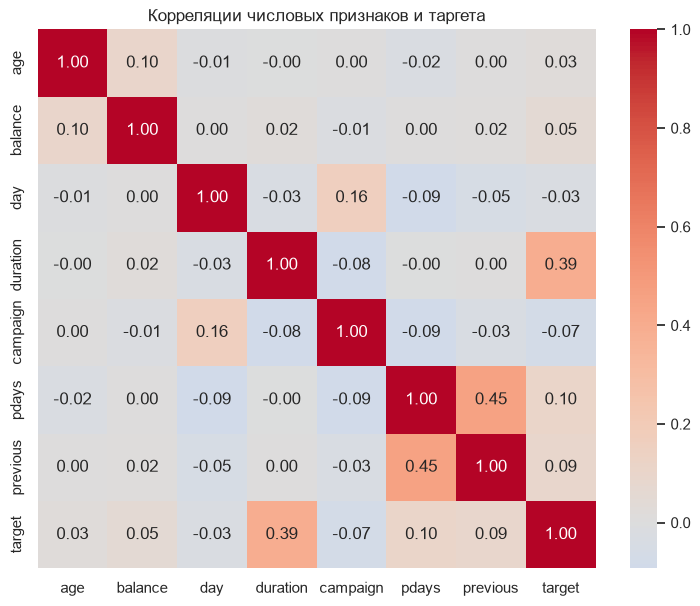

Отдельные попарные корреляции:
       previous  campaign
pdays     0.455    -0.089
day      -0.052     0.162


In [15]:
corr = work.select_dtypes("number").corr()
display(corr["target"].drop("target").sort_values(ascending=False).round(3))
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции числовых признаков и таргета")
plt.show()
print("Отдельные попарные корреляции:")
print(corr.loc[["pdays", "day"], ["previous", "campaign"]].round(3))

Самая высокая линейная связь с `target` у `duration` (около **0,395**). У большинства других числовых признаков она слабее. При этом `pdays` содержит специальное `-1`, поэтому его обычную числовую корреляцию нельзя трактовать без оговорок.

Для `pairplot()` надо взять небольшую выборку и четыре признака: иначе график будет перегруженным.

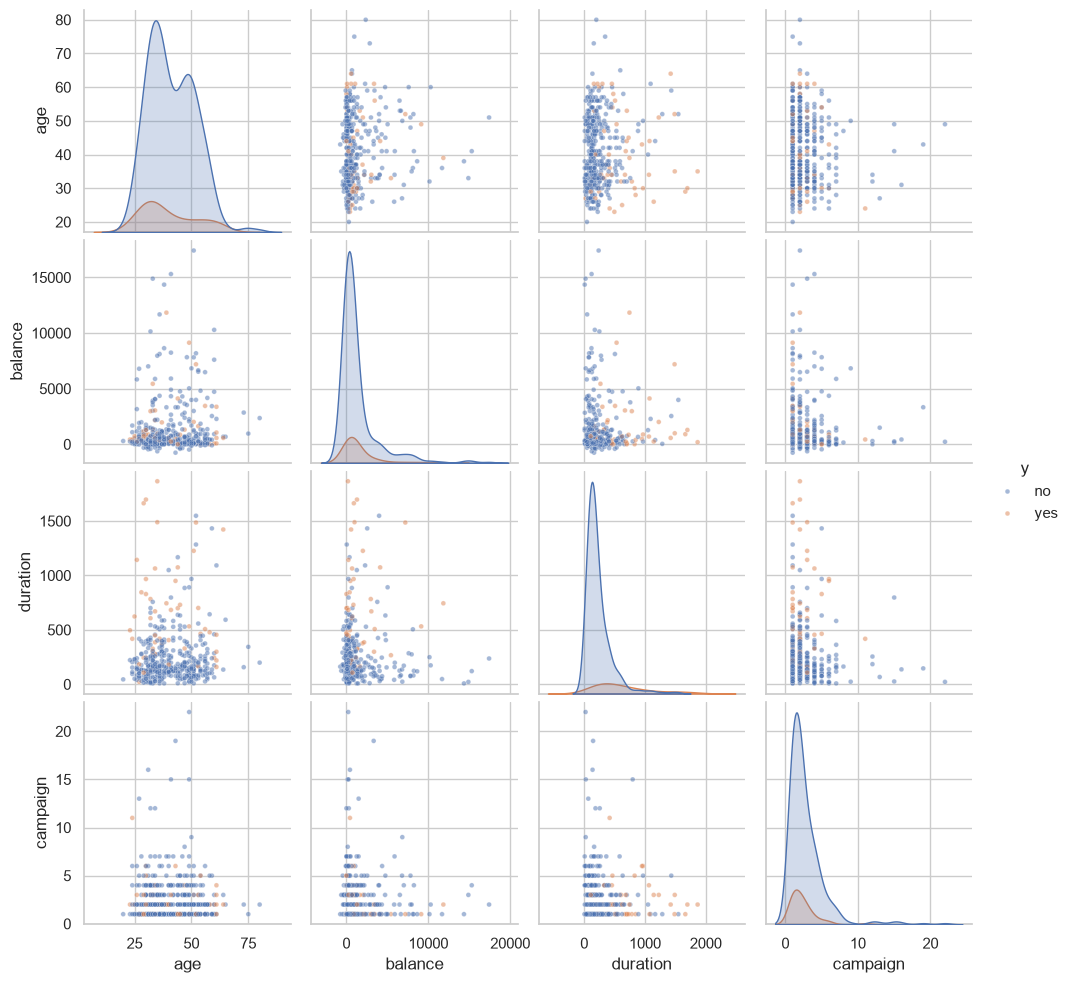

In [16]:
sample = df.sample(400, random_state=42)
sns.pairplot(sample, vars=["age", "balance", "duration", "campaign"],
             hue="y", plot_kws={"alpha": 0.5, "s": 12})
plt.show()

## 8. `duration` - утечка?

Сначала надо проверить, как меняется доля согласий между квартилями продолжительности звонка. Когда банк узнаёт длительность звонка?

In [17]:
quartiles = pd.qcut(work["duration"], 4, duplicates="drop")
t = work.groupby(quartiles, observed=True)["target"].agg(["size", "mean"])
t["mean"] = (100 * t["mean"]).round(2)
display(t)

,size,mean
duration,,
"(-0.001, 103.0]",11375,1.12
"(103.0, 180.0]",11285,5.16
"(180.0, 319.0]",11290,11.20
"(319.0, 4918.0]",11261,29.44


В квартиле самых коротких звонков `yes` - 1,12%, в квартиле самых длинных - 29,44%. Но `duration` становится известен только после разговора. Поэтому для задачи «кого выбрать для обзвона» этот признак недоступен на момент решения и не должен попадать в признаки модели - было указано в описании UCI.

Также надо уточнить момент прогнозирования для `campaign`, `day`, `month` и `contact`: сведения о текущей кампании не всегда известны до первого звонка. Точного года для каждого контакта нет, поэтому корректное строгое разбиение по времени из одного лишь `day`/`month` не восстановить.

## 9. Выводы и эталон для агента

1. **Задача:** бинарная классификация (`y`: `yes`/`no`), если нужно предсказывать отклик на депозит до звонка.
2. **Дисбаланс:** 11,70% положительного класса - выбор метрики должен зависеть от прикладной цели; один accuracy недостаточен.
3. **Пропуски:** формально `NaN` нет, но `unknown` нужно анализировать предметно. `pdays=-1` - не ошибка, а отсутствие прошлых контактов.
4. **Выбросы:** IQR применён к `age`, `balance`, `duration` и `campaign`; `pdays` и `previous` исследованы отдельно. Потенциальные выбросы не удалять автоматически.
5. **Ключевая проблема:** `duration` нельзя использовать для предсказания до звонка.
6. **Валидация:** случайное разбиение возможно только как техническая проверка; для реалистичной оценки по будущим кампаниям требуются данные о времени/кампаниях и соответствующее разделение.
7. **Для будущего агента:** ожидать распознавание типа задачи, таргета, дисбаланса, специальных значений, риска утечки и корректные уточнения о моменте прогноза.